In [5]:
import cv2
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import os

# Define relative paths pointing to our raw test files
# '..' tells Python to look in the parent directory of 'notebooks/'
IMAGE_PATH = os.path.join("..", "data", "raw", "image_001.jpg")
LABEL_PATH = os.path.join("..", "data", "raw", "image_001.txt")

# Let's verify our folder is set up properly and files exist
print(f"Image found successfully: {os.path.exists(IMAGE_PATH)}")
print(f"Label found successfully: {os.path.exists(LABEL_PATH)}")


Image found successfully: True
Label found successfully: True


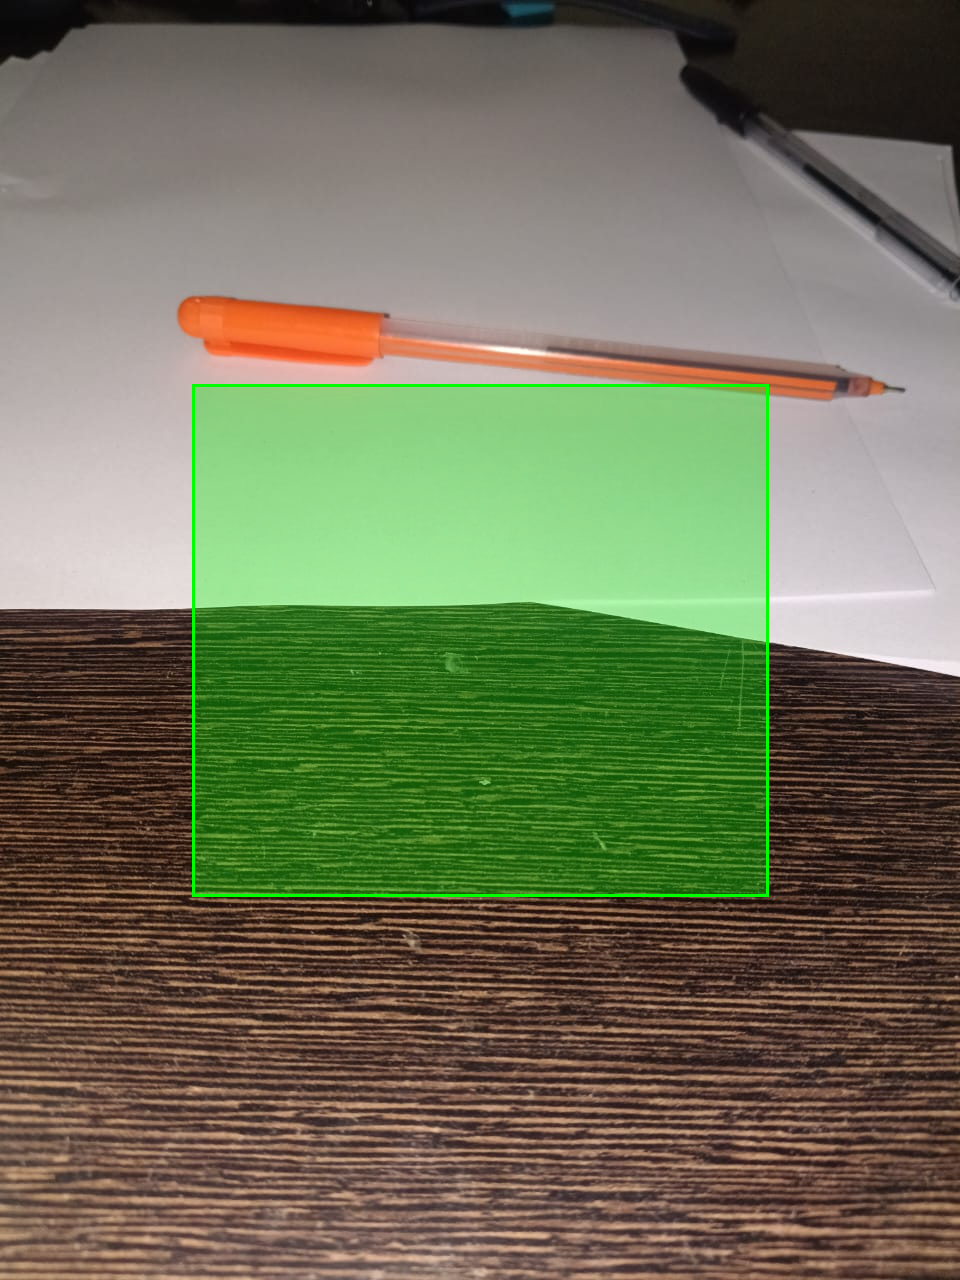

In [6]:
# 1. OpenCV: Load raw image and swap BGR to standard RGB color channels in RAM
cv2_img = cv2.imread(IMAGE_PATH)
rgb_img = cv2.cvtColor(cv2_img, cv2.COLOR_BGR2RGB)
height, width, _ = rgb_img.shape

# 2. Hand-off: Convert the raw NumPy pixel matrix directly into a Pillow Image Object
# This is a zero-copy operation, preserving computing memory on edge hardware
pil_img = Image.fromarray(rgb_img)

# Create an RGBA transparent drawing canvas on top of the Pillow Image
draw = ImageDraw.Draw(pil_img, "RGBA")

# 3. Read YOLO normalized coordinates from the label file
with open(LABEL_PATH, "r") as f:
    line = f.readline().strip()
    class_id, cx, cy, box_w, box_h = map(float, line.split())

# 4. Denormalize: Translate percentages back to exact pixel measurements
center_x = int(cx * width)
center_y = int(cy * height)
w = int(box_w * width)
h = int(box_h * height)

# 5. Coordinate Math: Convert Center/Width/Height to Top-Left and Bottom-Right corners
x1 = int(center_x - (w / 2))
y1 = int(center_y - (h / 2))
x2 = int(center_x + (w / 2))
y2 = int(center_y + (h / 2))

# 6. Pillow Drawing: Draw a beautiful, semi-transparent green highlighter box
# fill=(0, 255, 0, 80) is Green with ~31% opacity. outline=solid green border.
draw.rectangle(
    [x1, y1, x2, y2], 
    fill=(0, 255, 0, 80), 
    outline=(0, 255, 0, 255), 
    width=3
)

# 7. Render: Display the final polished image directly inside VS Code
display(pil_img)
